## 1. Setup & Package Imports
This cell installs the required packages and imports essential utilities for analysis, model pipeline creation, and validation.

In [18]:
%pip -q install -U xgboost catboost shap

import os, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, log_loss, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, classification_report)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
TRAIN_FILE = "/content/drive/MyDrive/Herts/Hackathon/dataset_B_training.csv"
TEST_FILE = "/content/drive/MyDrive/Herts/Hackathon/dataset_B_testing.csv"
EXAMPLE_FILE = "/content/drive/MyDrive/Herts/Hackathon/dataset_B_example_submission.csv"

if not all(os.path.exists(f) for f in [TRAIN_FILE, TEST_FILE, EXAMPLE_FILE]):
    from google.colab import files
    print("Upload training, testing and example submission CSV files")
    files.upload()

```markdown
## 2. Load & Validate Datasets
Here we load the data files, set up target labels, and execute sanity checks to ensure structural consistency.
```

## 2. Load & Validate Datasets
Here we load the data files, set up target labels, and execute sanity checks to ensure structural consistency.


In [19]:
train = pd.read_csv(TRAIN_FILE)
test = pd.read_csv(TEST_FILE)
example = pd.read_csv(EXAMPLE_FILE)
TARGET, ID = "h1n1_vaccine", "respondent_id"
assert TARGET in train and TARGET not in test
assert ID in train and ID in test and ID in example
assert train[ID].is_unique and test[ID].is_unique
assert train[TARGET].notna().all() and set(train[TARGET].unique()).issubset({0, 1})
feature_cols = [c for c in train.columns if c not in [ID, TARGET]]
assert len(feature_cols) == 29, f"Expected 29 features, got {len(feature_cols)}"
assert set(feature_cols) == set(test.columns) - {ID}, "Training/testing feature mismatch"
assert list(example.columns) == [ID, TARGET], "Review official example submission format"
assert len(example) == len(test)
assert example[ID].equals(test[ID]), "Example submission IDs/order differ from test file"
assert not train[ID].isin(test[ID]).any(), "Train/test respondent IDs overlap"
X = train[feature_cols].copy()
y = train[TARGET].astype(int)
X_test = test[feature_cols].copy()
print("Training:", train.shape, "Testing:", test.shape, "Submission example:", example.shape)
print("Features retained:", len(feature_cols), "Train missing cells:", int(X.isna().sum().sum()))
display(train.head(3))
display(pd.DataFrame({"dtype": X.dtypes.astype(str), "missing_train": X.isna().sum(),
                      "missing_test": X_test.isna().sum(), "unique_nonmissing": X.nunique()}).sort_values("missing_train", ascending=False))

Training: (4756, 31) Testing: (4749, 30) Submission example: (4749, 2)
Features retained: 29 Train missing cells: 6987


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1


,dtype,missing_train,missing_test,unique_nonmissing
employment_sector,object,2364,2405,21
health_insurance,float64,1925,1982,2
income_poverty,object,712,797,3
doctor_recc_h1n1,float64,319,345,2
rent_or_own,object,315,379,2
employment_status,object,235,277,3
marital_status,object,226,269,2
education,object,224,269,4
child_under_6_months,float64,134,155,2
health_worker,float64,131,149,2


## 3. Analyze Class Balance & Missing Values
We check target class counts, missing percentages per feature, and inspect correlations with vaccination outcomes.

Target counts:


,count
h1n1_vaccine,
Not vaccinated,2882
Vaccinated,1874


Target proportions:


,proportion
h1n1_vaccine,
0,0.605971
1,0.394029


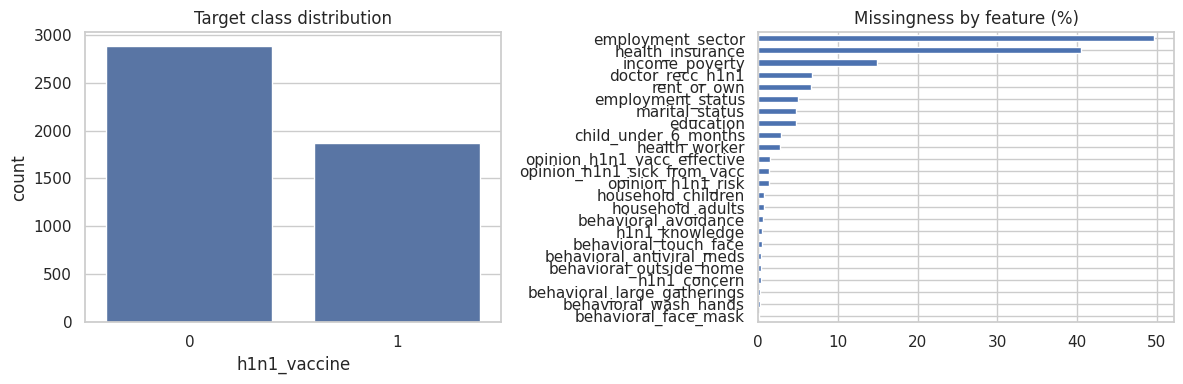

Numeric/encoded features: 19; text categories: 10


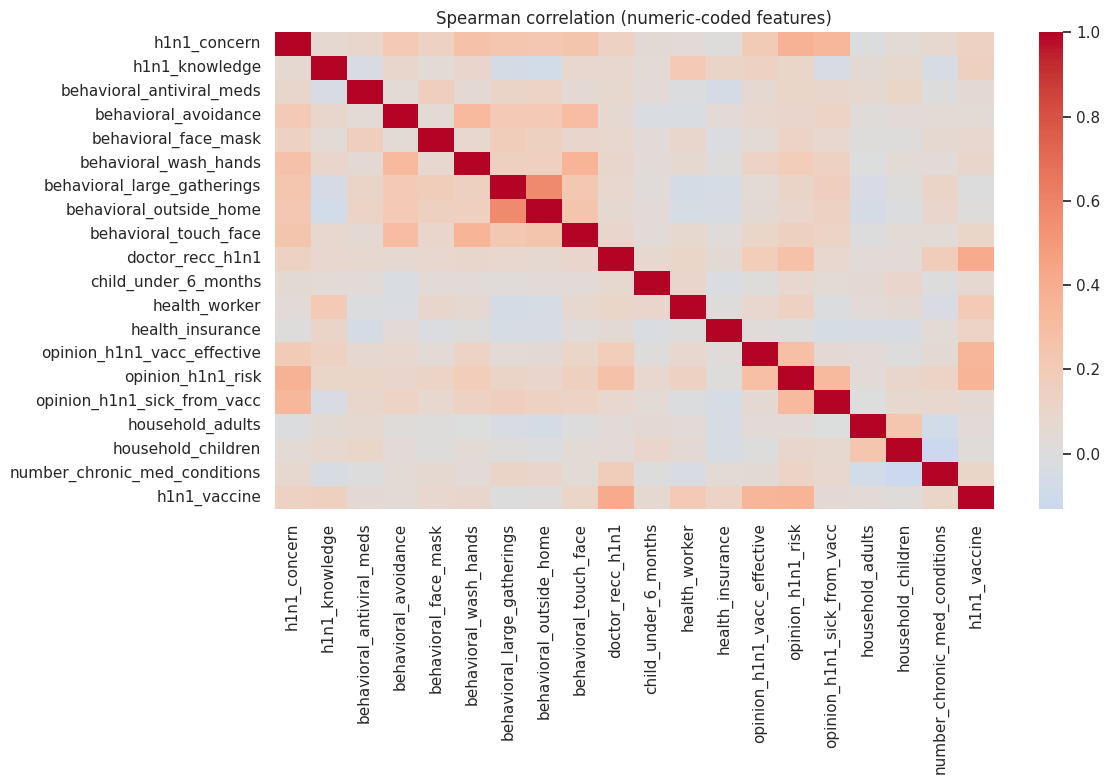

,feature,missing_pct,vaccinated_if_missing,vaccinated_if_observed
23,employment_sector,49.705635,0.384518,0.403428
12,health_insurance,40.475189,0.235844,0.501590
17,income_poverty,14.970563,0.365169,0.399110
9,doctor_recc_h1n1,6.707317,0.181818,0.409286
19,rent_or_own,6.623213,0.352381,0.396983
20,employment_status,4.941127,0.353191,0.396151
18,marital_status,4.751892,0.345133,0.396468
16,education,4.709840,0.321429,0.397617
10,child_under_6_months,2.817494,0.343284,0.395500
11,health_worker,2.754415,0.343511,0.395459


In [7]:
print("Target counts:")
display(y.value_counts().rename(index={0:"Not vaccinated",1:"Vaccinated"}).to_frame("count"))
print("Target proportions:")
display(y.value_counts(normalize=True).sort_index().to_frame("proportion"))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=y, ax=ax[0]); ax[0].set_title("Target class distribution")
missing_pct = X.isna().mean().mul(100).sort_values(ascending=False)
missing_pct[missing_pct > 0].sort_values().plot.barh(ax=ax[1]); ax[1].set_title("Missingness by feature (%)")
plt.tight_layout(); plt.show()

# Numeric features: distributions and rank-based correlations
numeric_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print(f"Numeric/encoded features: {len(numeric_cols)}; text categories: {len(cat_cols)}")
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(train[numeric_cols + [TARGET]].corr(method="spearman"), cmap="coolwarm", center=0, ax=ax)
ax.set_title("Spearman correlation (numeric-coded features)"); plt.tight_layout(); plt.show()

# Missingness can be informative: compare target rates for missing vs observed features
missing_summary = []
for c in feature_cols:
    m = train[c].isna()
    if m.any() and (~m).any():
        missing_summary.append({"feature":c, "missing_pct":100*m.mean(),
                                "vaccinated_if_missing":y[m].mean(),
                                "vaccinated_if_observed":y[~m].mean()})
display(pd.DataFrame(missing_summary).sort_values("missing_pct", ascending=False))

## 4. Explore Feature Relationships
This section visualizes relationship trends and evaluates vaccination rates across categories like doctor recommendations and demographics.




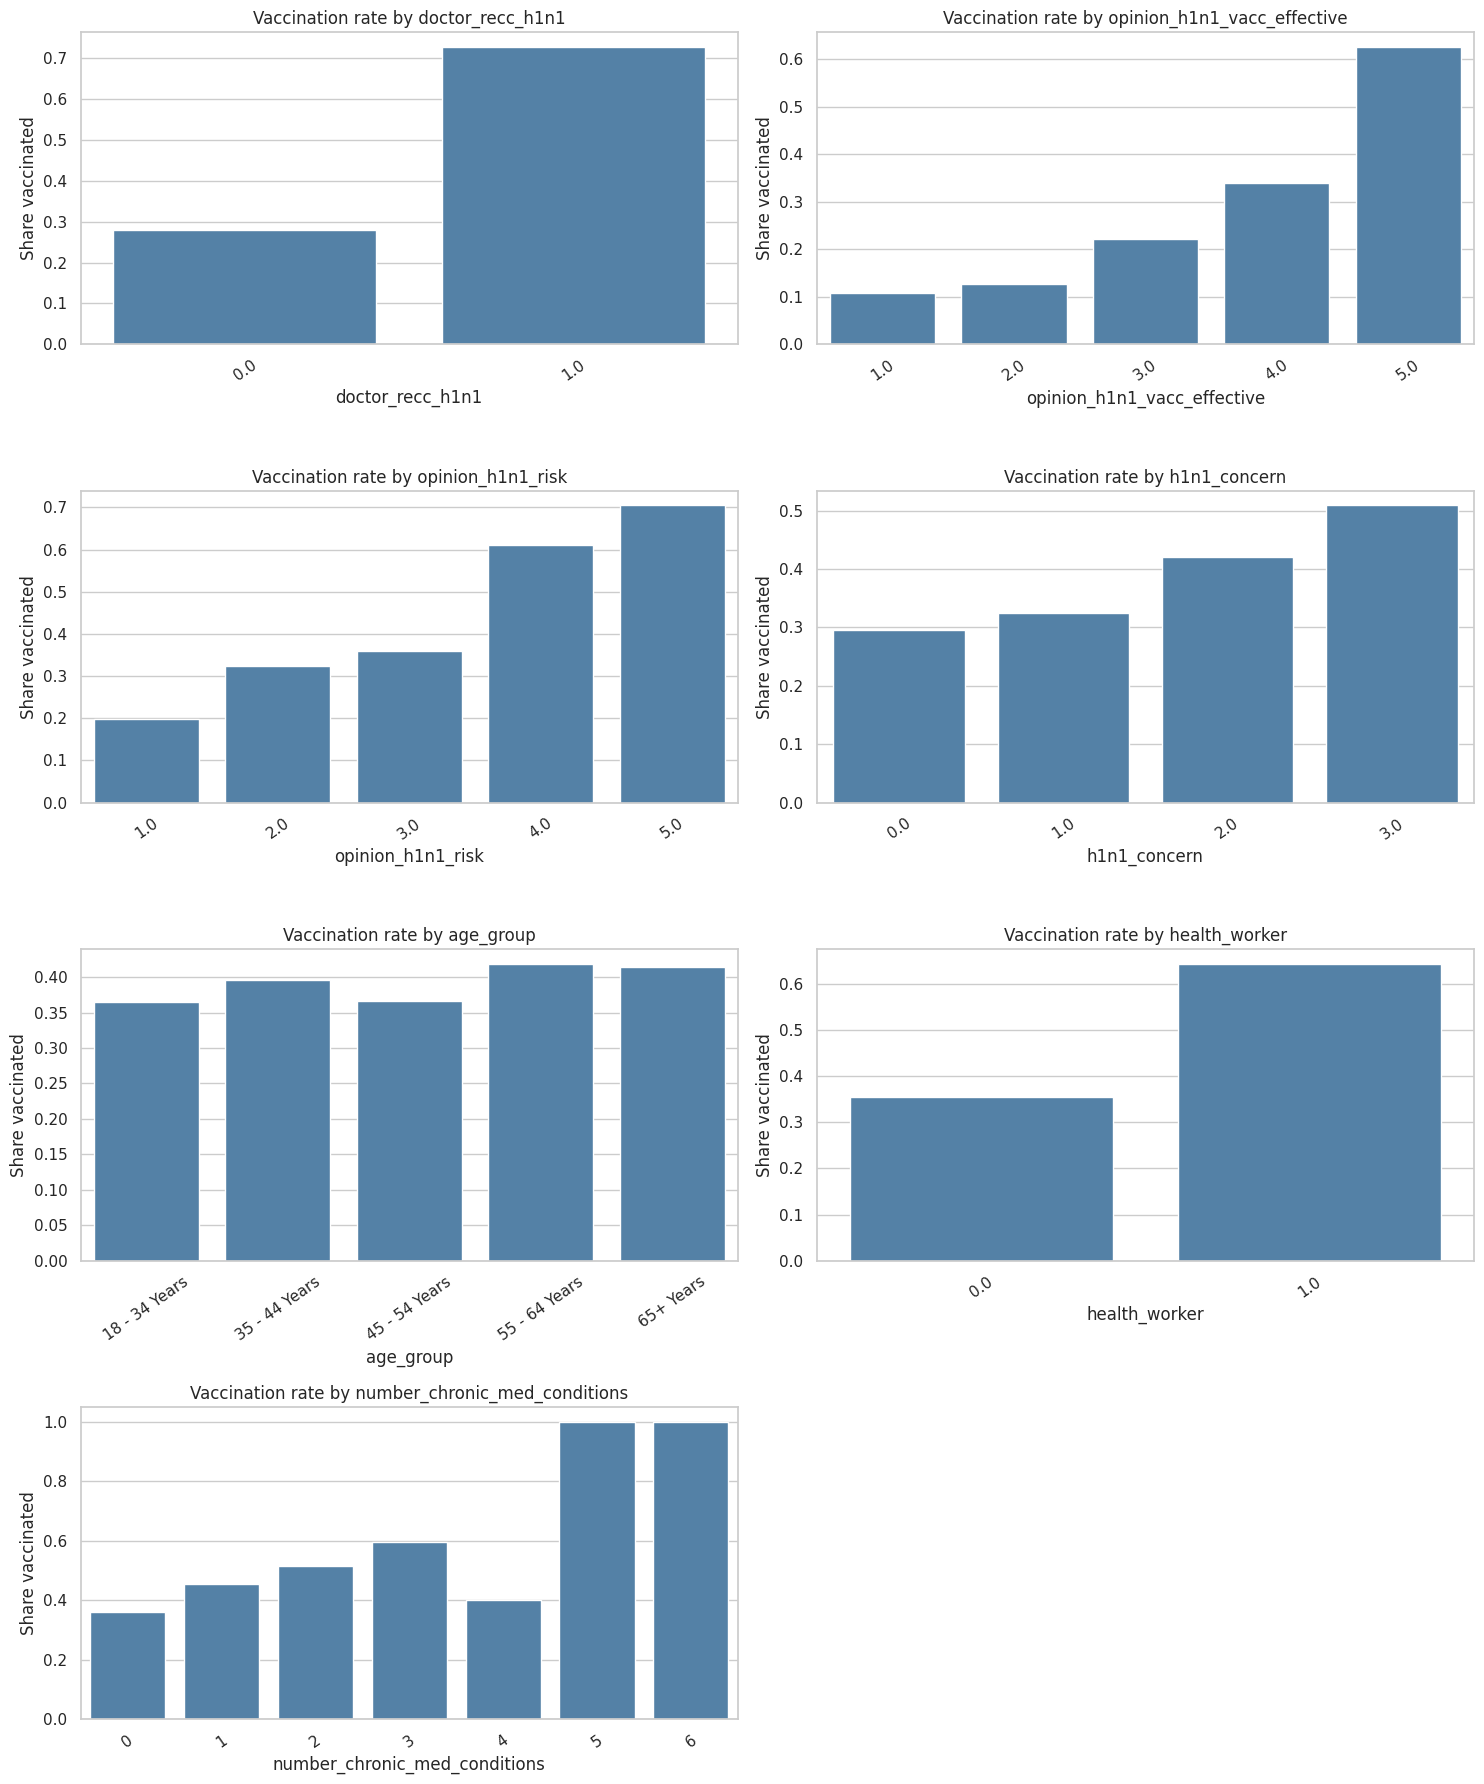


 age_group


,n,vaccination_rate
age_group,,
18 - 34 Years,894,0.364653
35 - 44 Years,659,0.396055
45 - 54 Years,913,0.365827
55 - 64 Years,1065,0.418779
65+ Years,1225,0.413878



 education


,n,vaccination_rate
education,,
12 Years,1009,0.323092
< 12 Years,395,0.324051
College Graduate,1858,0.444564
Some College,1270,0.411024
NaN,224,0.321429



 race


,n,vaccination_rate
race,,
Black,324,0.274691
Hispanic,296,0.405405
Other or Multiple,305,0.370492
White,3831,0.405116


... (10 outputs left out)


 census_msa


,n,vaccination_rate
census_msa,,
"MSA, Not Principle City",2120,0.390566
"MSA, Principle City",1383,0.395517
Non-MSA,1253,0.398244



 employment_sector


,n,vaccination_rate
employment_sector,,
administrative,14,0.500000
agriculture,162,0.259259
construction,168,0.250000
education,179,0.435754
energy,1,0.000000
entertainment,37,0.297297
finance,96,0.270833
government,55,0.381818
healthcare,546,0.637363


In [20]:
# Key vaccination relationships (rate, not raw counts, so groups are comparable)
plot_features = ["doctor_recc_h1n1", "opinion_h1n1_vacc_effective", "opinion_h1n1_risk",
                 "h1n1_concern", "age_group", "health_worker", "number_chronic_med_conditions"]
fig, axes = plt.subplots(4, 2, figsize=(15, 18))
for ax, c in zip(axes.flat, plot_features):
    rate = train.groupby(c, dropna=False)[TARGET].agg(["mean", "count"]).reset_index()
    sns.barplot(data=rate, x=c, y="mean", ax=ax, color="steelblue")
    ax.set_title(f"Vaccination rate by {c}")
    ax.set_ylabel("Share vaccinated")
    ax.tick_params(axis="x", rotation=35)
for ax in axes.flat[len(plot_features):]: ax.axis("off")
plt.tight_layout(); plt.show()

# All categorical levels retained and inspected
for c in cat_cols:
    print("\n", c)
    display(train.groupby(c, dropna=False)[TARGET].agg(["size", "mean"]).rename(columns={"size":"n", "mean":"vaccination_rate"}))

## 5. Splitting and Preprocessing Pipelines
We split the data into development/holdout sets and define transformations for numerical and categorical features.

In [9]:
X_dev, X_hold, y_dev, y_hold = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                     ("scale", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
                     ("onehot", encoder)])
preprocess = ColumnTransformer([("numeric", num_pipe, numeric_cols),
                                ("categorical", cat_pipe, cat_cols)], remainder="drop")
print("Development:", X_dev.shape, "Holdout:", X_hold.shape)

Development: (3804, 29) Holdout: (952, 29)


## 6. Model Evaluation (Cross-Validation)
We instantiate five classifiers and evaluate their baseline performance under Stratified 5-Fold Cross-Validation.




In [10]:
model_defs = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=250, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=180, learning_rate=0.06, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                             subsample=0.85, colsample_bytree=0.85, objective="binary:logistic",
                             eval_metric="logloss", tree_method="hist", n_jobs=2, random_state=SEED),
    "CatBoost": CatBoostClassifier(iterations=350, depth=5, learning_rate=0.05,
                                    loss_function="Logloss", verbose=False, thread_count=2, random_seed=SEED)
}
models = {name: Pipeline([("prep", preprocess), ("model", estimator)])
          for name, estimator in model_defs.items()}
models["Majority baseline"] = Pipeline([("prep", preprocess),
                                         ("model", DummyClassifier(strategy="prior"))])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"auc":"roc_auc", "f1":"f1", "balanced_accuracy":"balanced_accuracy", "neg_log_loss":"neg_log_loss"}
cv_rows = []
for name, pipe in models.items():
    print("Cross-validating:", name)
    scores = cross_validate(pipe, X_dev, y_dev, scoring=scoring, cv=cv, n_jobs=1, error_score="raise")
    cv_rows.append({"model":name, "cv_auc_mean":scores["test_auc"].mean(),
                    "cv_auc_sd":scores["test_auc"].std(), "cv_f1_mean":scores["test_f1"].mean(),
                    "cv_balanced_acc_mean":scores["test_balanced_accuracy"].mean(),
                    "cv_log_loss_mean":-scores["test_neg_log_loss"].mean()})
cv_table = pd.DataFrame(cv_rows).sort_values("cv_auc_mean", ascending=False)
display(cv_table.round(4))
cv_table.to_csv("cross_validation_results.csv", index=False)

Cross-validating: Logistic Regression
Cross-validating: Random Forest
Cross-validating: Hist Gradient Boosting
Cross-validating: XGBoost
Cross-validating: CatBoost
Cross-validating: Majority baseline


,model,cv_auc_mean,cv_auc_sd,cv_f1_mean,cv_balanced_acc_mean,cv_log_loss_mean
3,XGBoost,0.8570,0.0095,0.7223,0.7741,0.4534
4,CatBoost,0.8570,0.0100,0.7225,0.7744,0.4520
1,Random Forest,0.8535,0.0110,0.6991,0.7584,0.4745
2,Hist Gradient Boosting,0.8534,0.0071,0.7174,0.7695,0.4623
0,Logistic Regression,0.8485,0.0090,0.7217,0.7678,0.4806
5,Majority baseline,0.5000,0.0000,0.0000,0.5000,0.6705


## 7. Hyperparameter Tuning
We optimize parameters for each classifier using randomized search to find the best configuration for ROC-AUC.

In [11]:
tuning_spaces = {
    "Logistic Regression": {"model__C":[0.03, 0.1, 0.3, 1, 3, 10], "model__class_weight":[None, "balanced"]},
    "Random Forest": {"model__n_estimators":[150, 250, 400], "model__max_depth":[None, 6, 12],
                      "model__min_samples_leaf":[1, 2, 5]},
    "Hist Gradient Boosting": {"model__max_iter":[100, 180, 280], "model__learning_rate":[0.03, 0.06, 0.1],
                               "model__max_leaf_nodes":[15, 31, 63], "model__l2_regularization":[0, 0.5, 2]},
    "XGBoost": {"model__max_depth":[2, 3, 4, 5], "model__learning_rate":[0.03, 0.05, 0.1],
                "model__n_estimators":[150, 300, 450], "model__min_child_weight":[1, 3, 6]},
    "CatBoost": {"model__depth":[4, 5, 6], "model__learning_rate":[0.03, 0.05, 0.1],
                 "model__iterations":[200, 350, 500], "model__l2_leaf_reg":[1, 3, 7]}
}
N_ITER = 6  # Increase if time allows
searches, tuned_models, tuning_rows = {}, {}, []
for name in model_defs:
    print("Tuning:", name)
    search = RandomizedSearchCV(models[name], tuning_spaces[name], n_iter=N_ITER,
                                scoring="roc_auc", cv=cv, random_state=SEED,
                                n_jobs=1, refit=True, error_score="raise")
    search.fit(X_dev, y_dev)
    searches[name] = search
    tuned_models[name] = search.best_estimator_
    tuning_rows.append({"model":name, "best_cv_auc":search.best_score_,
                        "best_parameters":str(search.best_params_)})
tuning_table = pd.DataFrame(tuning_rows).sort_values("best_cv_auc", ascending=False)
display(tuning_table)
tuning_table.to_csv("tuning_results.csv", index=False)

Tuning: Logistic Regression
Tuning: Random Forest
Tuning: Hist Gradient Boosting
Tuning: XGBoost
Tuning: CatBoost


,model,best_cv_auc,best_parameters
4,CatBoost,0.857668,"{'model__learning_rate': 0.03, 'model__l2_leaf..."
2,Hist Gradient Boosting,0.857108,"{'model__max_leaf_nodes': 31, 'model__max_iter..."
3,XGBoost,0.856198,"{'model__n_estimators': 450, 'model__min_child..."
1,Random Forest,0.855341,"{'model__n_estimators': 400, 'model__min_sampl..."
0,Logistic Regression,0.850237,"{'model__class_weight': None, 'model__C': 0.03}"


## 8. Holdout Validation & Diagnostics
We evaluate the tuned models on the unseen holdout set and plot comparative ROC and Precision-Recall curves.

,model,auc,accuracy,balanced_accuracy,f1,precision,recall,log_loss,brier,FP,FN,TP,TN
3,XGBoost,0.8457,0.7826,0.7660,0.7137,0.7414,0.6880,0.4714,0.1533,90,117,258,487
4,CatBoost,0.8450,0.7826,0.7609,0.7047,0.7577,0.6587,0.4696,0.1523,79,128,247,498
2,Hist Gradient Boosting,0.8411,0.7763,0.7566,0.7004,0.7411,0.6640,0.4760,0.1549,87,126,249,490
0,Logistic Regression,0.8380,0.7784,0.7555,0.6973,0.7547,0.6480,0.4801,0.1563,79,132,243,498
1,Random Forest,0.8332,0.7679,0.7375,0.6687,0.7637,0.5947,0.5006,0.1631,69,152,223,508


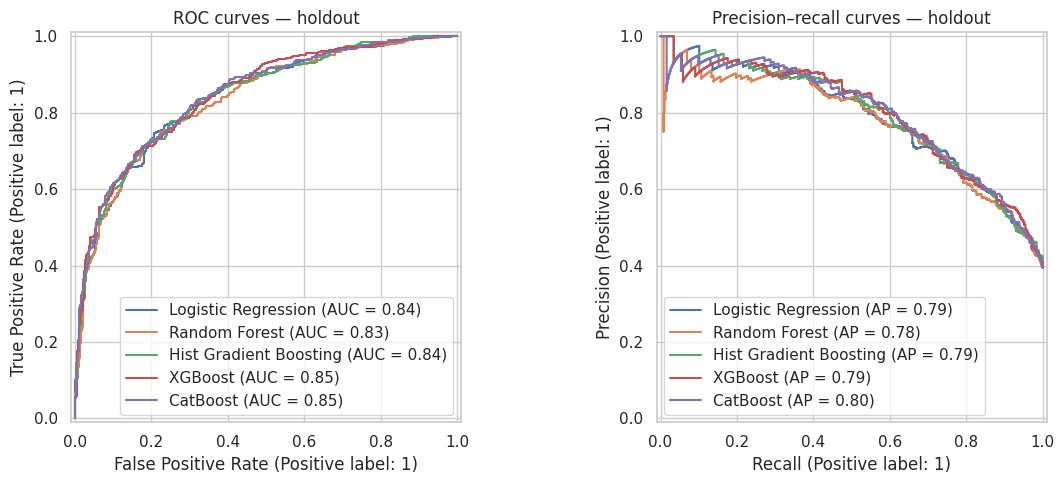

Preselected best model by development CV: CatBoost


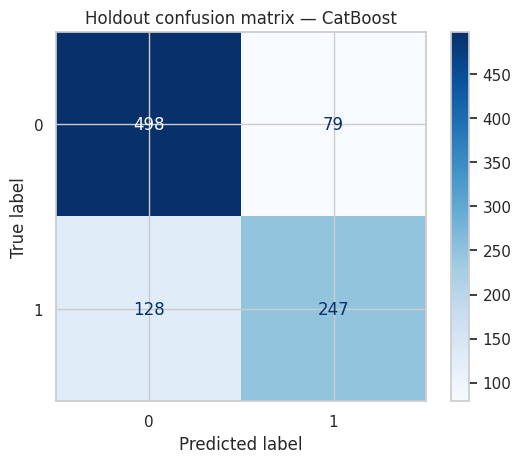

              precision    recall  f1-score   support

           0      0.796     0.863     0.828       577
           1      0.758     0.659     0.705       375

    accuracy                          0.783       952
   macro avg      0.777     0.761     0.766       952
weighted avg      0.781     0.783     0.779       952



In [12]:
holdout_rows = []
for name, pipe in tuned_models.items():
    proba = pipe.predict_proba(X_hold)[:, 1]
    pred = (proba >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_hold, pred, labels=[0,1]).ravel()
    holdout_rows.append({"model":name, "auc":roc_auc_score(y_hold, proba),
                         "accuracy":accuracy_score(y_hold, pred),
                         "balanced_accuracy":balanced_accuracy_score(y_hold, pred),
                         "f1":f1_score(y_hold, pred), "precision":precision_score(y_hold, pred, zero_division=0),
                         "recall":recall_score(y_hold, pred), "log_loss":log_loss(y_hold, proba),
                         "brier":brier_score_loss(y_hold, proba),
                         "FP":int(fp), "FN":int(fn), "TP":int(tp), "TN":int(tn)})
holdout_table = pd.DataFrame(holdout_rows).sort_values("auc", ascending=False)
display(holdout_table.round(4))
holdout_table.to_csv("holdout_model_comparison.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, pipe in tuned_models.items():
    p = pipe.predict_proba(X_hold)[:, 1]
    RocCurveDisplay.from_predictions(y_hold, p, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_hold, p, name=name, ax=axes[1])
axes[0].set_title("ROC curves — holdout"); axes[1].set_title("Precision–recall curves — holdout")
plt.tight_layout(); plt.show()

best_name = tuning_table.iloc[0]["model"]  # selected by development CV, NOT holdout
best_pipe = tuned_models[best_name]
print("Preselected best model by development CV:", best_name)
ConfusionMatrixDisplay.from_estimator(best_pipe, X_hold, y_hold, labels=[0,1], cmap="Blues")
plt.title(f"Holdout confusion matrix — {best_name}"); plt.show()
print(classification_report(y_hold, best_pipe.predict(X_hold), digits=3))

## 9. Threshold Tuning & Cost Analysis
We experiment with different classification thresholds to find the ideal balance between precision and recall.


,threshold,precision,recall,f1,predicted_vaccinated,FP,FN
0,0.10,0.462,0.965,0.625,784,422,13
1,0.15,0.513,0.928,0.660,679,331,27
2,0.20,0.564,0.899,0.693,598,261,38
3,0.25,0.602,0.848,0.704,528,210,57
4,0.30,0.637,0.808,0.712,476,173,72
5,0.35,0.658,0.760,0.705,433,148,90
6,0.40,0.685,0.741,0.712,406,128,97
7,0.45,0.726,0.712,0.719,368,101,108
8,0.50,0.758,0.659,0.705,326,79,128
9,0.55,0.799,0.616,0.696,289,58,144


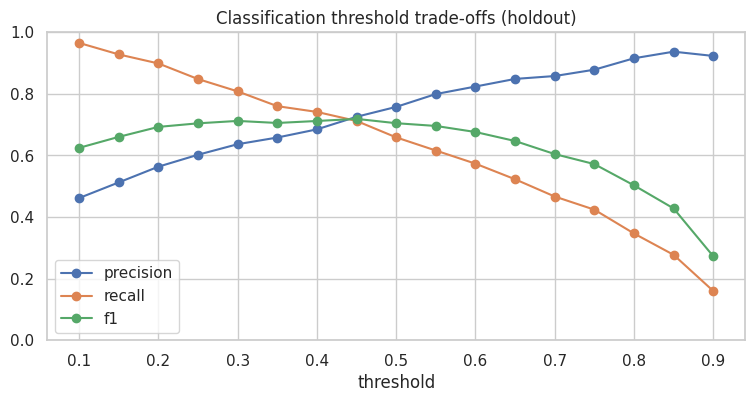

Given costs: 500 25000
A valid expected-cost objective requires e.g. H1N1 infection probability, hospitalisation risk, vaccine efficacy and decision policy.
Do not treat vaccination labels as hospitalisation outcomes.


In [13]:
best_probs = best_pipe.predict_proba(X_hold)[:,1]
threshold_rows = []
for t in np.arange(0.10, 0.91, 0.05):
    pred = (best_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_hold, pred, labels=[0,1]).ravel()
    threshold_rows.append({"threshold":round(float(t),2), "precision":precision_score(y_hold,pred,zero_division=0),
                           "recall":recall_score(y_hold,pred,zero_division=0),
                           "f1":f1_score(y_hold,pred,zero_division=0),
                           "predicted_vaccinated":int(pred.sum()), "FP":int(fp), "FN":int(fn)})
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(3))
threshold_table.plot(x="threshold", y=["precision","recall","f1"], figsize=(9,4), marker="o")
plt.title("Classification threshold trade-offs (holdout)"); plt.ylim(0,1); plt.show()

VACCINE_COST = 500
HOSPITALISATION_COST = 25000
print("Given costs:", VACCINE_COST, HOSPITALISATION_COST)
print("A valid expected-cost objective requires e.g. H1N1 infection probability, hospitalisation risk, vaccine efficacy and decision policy.")
print("Do not treat vaccination labels as hospitalisation outcomes.")

## 10. Permutation Feature Importance
We measure feature importance by shuffling values and calculating the corresponding drop in validation ROC-AUC.


,feature,mean_auc_drop,sd
9,doctor_recc_h1n1,0.069962,0.005284
12,health_insurance,0.067710,0.009209
13,opinion_h1n1_vacc_effective,0.039585,0.007696
14,opinion_h1n1_risk,0.034907,0.008087
11,health_worker,0.010209,0.001781
16,age_group,0.003779,0.001730
17,education,0.003603,0.001575
27,employment_sector,0.003542,0.000964
18,race,0.003449,0.001062
1,h1n1_knowledge,0.003207,0.001176


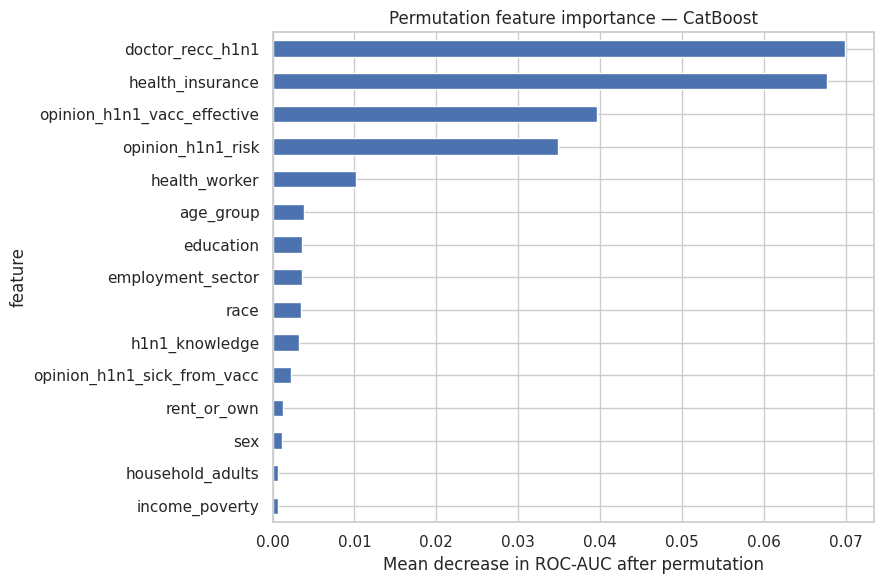

In [14]:
perm = permutation_importance(best_pipe, X_hold, y_hold, scoring="roc_auc", n_repeats=5,
                              random_state=SEED, n_jobs=1)
importance = pd.DataFrame({"feature":feature_cols, "mean_auc_drop":perm.importances_mean,
                           "sd":perm.importances_std}).sort_values("mean_auc_drop", ascending=False)
display(importance.head(20))
importance.to_csv("permutation_importance.csv", index=False)
importance.head(15).sort_values("mean_auc_drop").plot.barh(x="feature", y="mean_auc_drop", legend=False, figsize=(9,6))
plt.xlabel("Mean decrease in ROC-AUC after permutation")
plt.title(f"Permutation feature importance — {best_name}")
plt.tight_layout(); plt.show()

In [15]:
simple_prep = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                           ("scale", StandardScaler())]), numeric_cols),
    ("categorical", cat_pipe, cat_cols)
])
comparison = []
for label, prep in [("median + indicators", preprocess), ("most frequent", simple_prep)]:
    candidate = Pipeline([("prep", prep),
                          ("model", LogisticRegression(max_iter=2000, random_state=SEED))])
    score = cross_validate(candidate, X_dev, y_dev, cv=cv, scoring="roc_auc", n_jobs=1)["test_score"]
    comparison.append({"preprocessing":label, "mean_cv_auc":score.mean(), "sd_cv_auc":score.std()})
display(pd.DataFrame(comparison))

,preprocessing,mean_cv_auc,sd_cv_auc
0,median + indicators,0.848810,0.009208
1,most frequent,0.822351,0.006584


In [16]:
SUBMISSION_TYPE = "binary"  # choose "probability" ONLY if official instructions require it
assert SUBMISSION_TYPE in ["binary", "probability"]
ranked_names = tuning_table.sort_values("best_cv_auc", ascending=False)["model"].tolist()
assert len(ranked_names) == 5
submission_manifest = []
for rank, name in enumerate(ranked_names, 1):
    # Clone fitted pipeline so tuning results and holdout experiments remain unchanged
    from sklearn.base import clone
    final_pipe = clone(tuned_models[name])
    final_pipe.fit(X, y)
    probs = final_pipe.predict_proba(X_test)[:,1]
    values = probs if SUBMISSION_TYPE == "probability" else (probs >= 0.5).astype(int)
    submission = example.copy()
    submission[TARGET] = values
    assert submission.shape == example.shape
    assert submission[ID].equals(test[ID])
    assert submission[TARGET].notna().all()
    assert submission[TARGET].between(0,1).all()
    if SUBMISSION_TYPE == "binary":
        assert set(submission[TARGET].unique()).issubset({0,1})
    filename = f"{rank}_dataset_B_{name.lower().replace(' ','_')}.csv"
    submission.to_csv(filename, index=False)
    submission_manifest.append({"rank":rank, "model":name, "file":filename,
                                "development_cv_auc":float(tuning_table.set_index("model").loc[name,"best_cv_auc"]),
                                "prediction_type":SUBMISSION_TYPE,
                                "predicted_positive_rate":float(np.mean(values >= 0.5))})
manifest = pd.DataFrame(submission_manifest)
display(manifest)
manifest.to_csv("submission_manifest.csv", index=False)
print("Created all 5 submission files. Confirm the official metric and submission type before submitting.")

,rank,model,file,development_cv_auc,prediction_type,predicted_positive_rate
0,1,CatBoost,1_dataset_B_catboost.csv,0.857668,binary,0.346389
1,2,Hist Gradient Boosting,2_dataset_B_hist_gradient_boosting.csv,0.857108,binary,0.344072
2,3,XGBoost,3_dataset_B_xgboost.csv,0.856198,binary,0.361339
3,4,Random Forest,4_dataset_B_random_forest.csv,0.855341,binary,0.317751
4,5,Logistic Regression,5_dataset_B_logistic_regression.csv,0.850237,binary,0.343651


Created all 5 submission files. Confirm the official metric and submission type before submitting.


In [17]:
import zipfile
outputs = manifest["file"].tolist() + ["submission_manifest.csv", "cross_validation_results.csv",
                                         "tuning_results.csv", "holdout_model_comparison.csv", "permutation_importance.csv"]
with zipfile.ZipFile("H1N1_Dataset_B_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in outputs:
        if os.path.exists(f): z.write(f)
print("Saved H1N1_Dataset_B_outputs.zip")
# Uncomment for a browser download in Colab:
# from google.colab import files
# files.download("H1N1_Dataset_B_outputs.zip")

Saved H1N1_Dataset_B_outputs.zip
